# Visualisation & Analysis: Molecular Size & Hydrogen Bonding vs. Antipathogen Activity (EC50)

**Reading Dataset**

In [9]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

root_dir = str(Path(os.getcwd()).parent)
mmv_dataset = Path(root_dir, 'data/mmv_ChEMBL-IC50s-Sep2026.csv')

mmv_compounds_df = pd.read_csv(mmv_dataset, delimiter='\t')


**Isolating Relevant Columns & Data**

In [10]:
size_h_bonding_columns = ['molecular_weight', 'heavy_atoms', 'hba', 'hbd']

In [29]:
size_h_bonding_df = mmv_compounds_df.dropna(subset=size_h_bonding_columns).copy()

size_h_bonding_df = size_h_bonding_df[size_h_bonding_df['pf_ec50_uM'] > 0 ] # ensures for valid & positive values


## Molecular Weight vs EC50

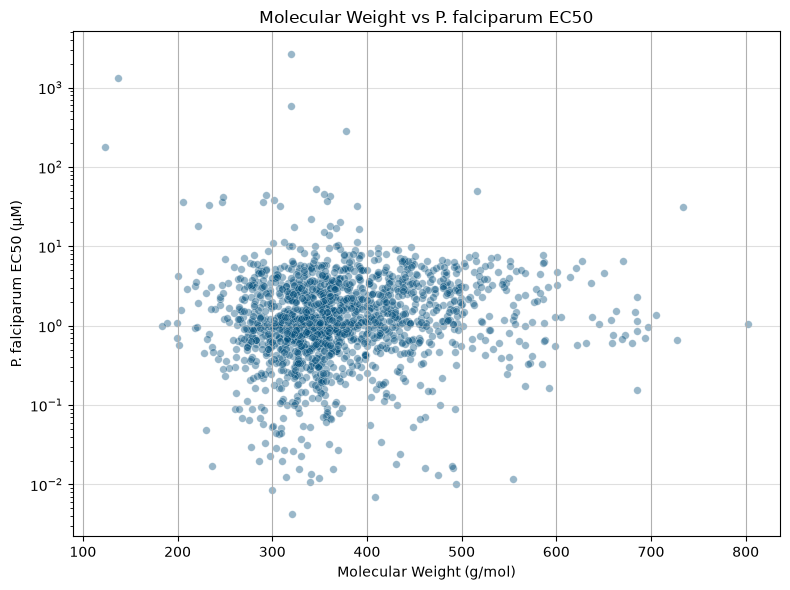

In [134]:
molecular_weight_column = size_h_bonding_df['molecular_weight']
chembl_id_column = size_h_bonding_df['chembl_id']
activity_column = size_h_bonding_df['pf_ec50_uM']


plt.figure(figsize=(8,6))
sns.scatterplot(x=molecular_weight_column, 
                y=activity_column, 
                alpha=0.4, 
                s=30,
                color="#004D7A")


plt.yscale('log', base=10)
plt.xlabel('Molecular Weight (g/mol)')
plt.ylabel('P. falciparum EC50 (µM)')
plt.title("Molecular Weight vs P. falciparum EC50")
plt.grid(axis='y', alpha=0.4)
plt.grid(True)
plt.tight_layout()
plt.show()



- **Plot:** Scatter plot with EC50 axis scaled to log(10), to be able to analyse relationships between two numerical variables across a wide activity range.

- **Findings:** A weak positive correlation (spearman ρ = +0.156). Higher molecular weights are slightly associated with higher EC50 values, but there is still substantial variation present.

- **Significance:** Molecular weight alone is a weak indicator of antipathogen activity. Higher EC50 indicates lower potency, but the observed correlation does not verify causation.

## Heavy Atoms vs EC50

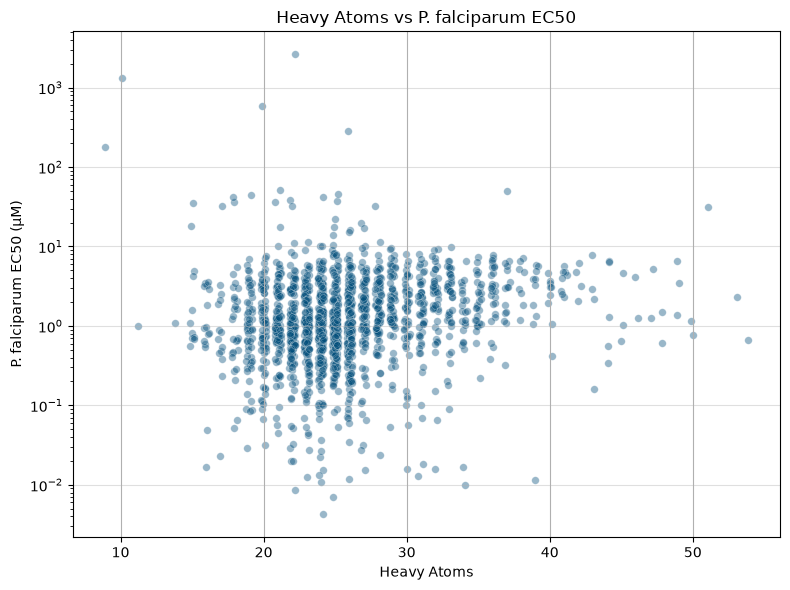

In [135]:
heavy_atoms_column = size_h_bonding_df['heavy_atoms']

x_jittered = size_h_bonding_df['heavy_atoms'] + \
    np.random.default_rng(42).uniform(
        -0.2, 0.2, len(size_h_bonding_df)
    ) # to separate the overlapping dots more


plt.figure(figsize=(8,6))
sns.scatterplot(y=activity_column, 
                x=x_jittered, 
                alpha=0.4, 
                s=30,
                color="#004D7A")


plt.yscale('log', base=10)
plt.xlabel('Heavy Atoms')
plt.ylabel('P. falciparum EC50 (µM)')
plt.title("Heavy Atoms vs P. falciparum EC50")
plt.grid(axis='y', alpha=0.4)
plt.grid(True)
plt.tight_layout()
plt.show()



- **Plot:** Jittered scatter plot, to analyse discrete numerical numbers and visualise overlapping data.

- **Findings:** A weak positive correlation (ρ = +0.219), indicating compounds with more heavy atoms have a slightly higher EC50 values.

- **Significance:** Heavy atom amount have the strongest positive relationship compared to the 4 other properties, but association is still weak and does not verify causation.


## HBA vs EC50

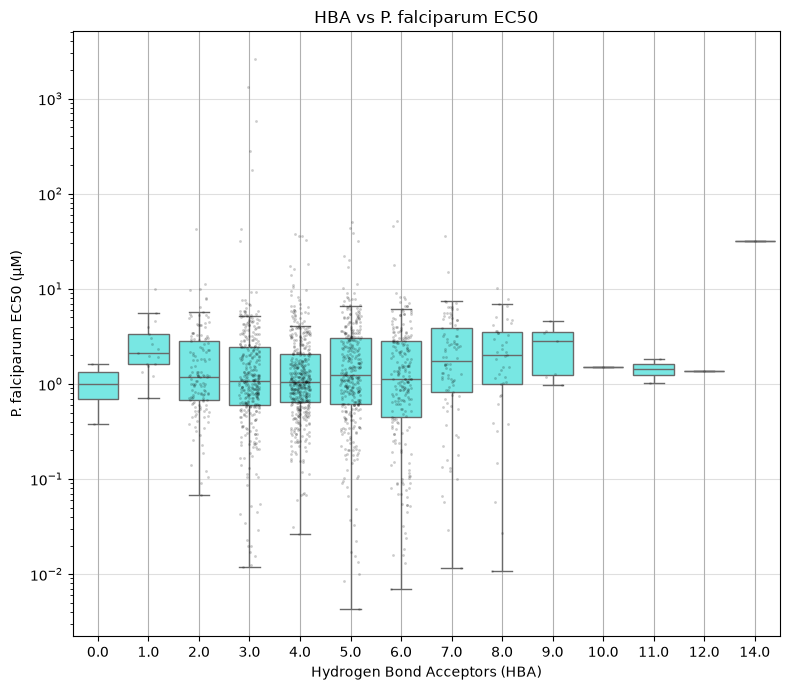

In [129]:
hba_column = size_h_bonding_df['hba']



plt.figure(figsize=(8,7))
sns.boxplot(x=hba_column,
            y=activity_column,
            showfliers=False, # removes any duplicate outlier markers
            color="#66f9f4")


sns.stripplot(x=hba_column,
              y=activity_column,
              color='black',
              alpha=0.2,
              size=2,
              jitter=0.20) # individual points to show all data


plt.yscale('log', base=10)
plt.xlabel('Hydrogen Bond Acceptors (HBA)')
plt.ylabel('P. falciparum EC50 (µM)')
plt.title("HBA vs P. falciparum EC50")
plt.grid(axis='y', alpha=0.4)
plt.grid(True)
plt.tight_layout()
plt.show()


- **Plot:** Box plot with individual dots, to compare the median EC50 values and variability across discrete HBA counts.

- **Findings:** Very weak positive correlation (spearman ρ = +0.047). Most compounds contain 3–6 acceptors, with substantially overlapping EC50 distributions.

- **Significance:** No clear overall relationship is observed and provides limited information about antipathogen potency.

- **Limitation:** High HBA counts are uncommon, making their distributions less reliable for comparison.

## HBD vs EC50

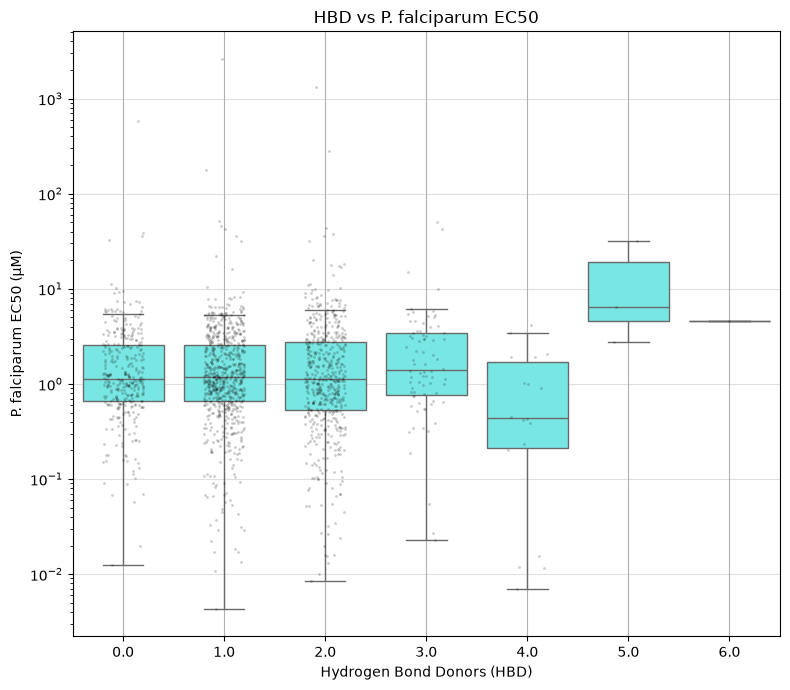

In [130]:
hbd_column = size_h_bonding_df['hbd']


plt.figure(figsize=(8,7))
sns.boxplot(x=hbd_column,
            y=activity_column,
            showfliers=False,
            color='#66f9f4')


sns.stripplot(x=hbd_column,
              y=activity_column,
              color='black',
              alpha=0.2,
              size=2,
              jitter=0.20)


plt.yscale('log', base=10)
plt.xlabel('Hydrogen Bond Donors (HBD)')
plt.ylabel('P. falciparum EC50 (µM)')
plt.title("HBD vs P. falciparum EC50")
plt.grid(axis='y', alpha=0.4)
plt.grid(True)
plt.tight_layout()
plt.show()


- **Plot:** Box plot with individual dots, to compare the median EC50 values and variability across discrete HBA counts.

- **Findings:** Very weak positive correlation (spearman ρ = +0.047). Compounds with 0-2 donors show similar median EC50 values.

- **Significance:** No clear overall relationship is observed and provides limited information about antipathogen potency.

- **Limitation:** Only a few compounds have 4 or more HBDs, giving less information about these groups to come to a solid conclusion.